# Circuit imaging: which features does the scalar approximation misrepresent?

Use a **schematic circuit mask**, rather than isolated test bars. It contains a group of vertical traces, a group of horizontal traces, nested bends, T-junctions and pads, so changing the incident polarization has an observable spatial meaning.

We first project this reticle with a visible-light ideal lens. We then use an ideal 193 nm, 4× reduction relay with annular partial coherence and compare **the same scalar reference with x and y vector illumination**. Two magnified regions and their line profiles resolve the field and polarization inside individual trace groups.

The mask is a schematic drawn in the notebook, not a fabrication-ready layout. The objective is an ideal aplanatic angular-pupil model. Thin-mask transmission, optical projection and exposure chemistry are distinct models; this notebook implements the first two, not resist development.

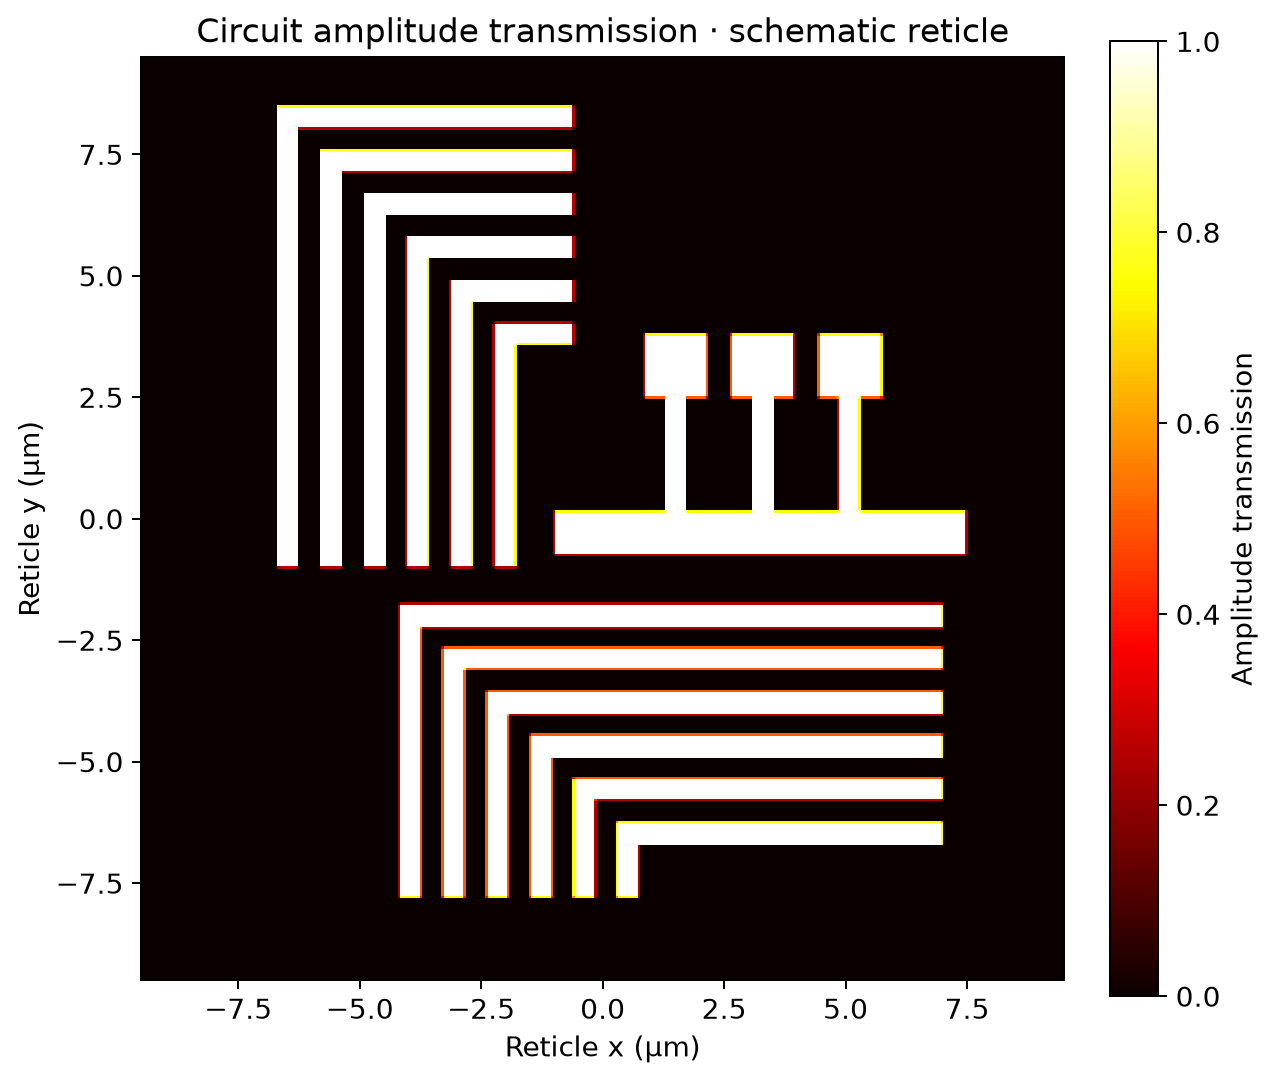

Reticle raster width: 17.92 µm; mask pixel: 0.032 µm


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import Normalize, PowerNorm
from matplotlib.patches import Rectangle
from scipy.ndimage import map_coordinates
from vecdiff_general.fourier.cartesian import FFT2, frequency_grid
from vecdiff_general.propagation.imaging import (
    apply_pupil,
    image_spectrum,
    scalar_image,
)
from vecdiff_general.visualization import plot_intensity

%matplotlib inline

plt.rcParams.update({"figure.dpi": 180, "font.size": 11})
um = 1e-6
air = optics.HomogeneousRegion("air", optics.Dielectric(1))
incident_power = 1e-12
mask_pixel = 0.032 * um
trace, pitch = 0.448, 0.896  # reticle µm: 112 nm lines at 224 nm pitch on the wafer


def draw_circuit(pixels=560):
    """Binary reticle transmission (rows along +y) from rectangles in reticle µm."""
    axis = (np.arange(pixels) - (pixels - 1) / 2) * mask_pixel / um
    x, y = np.meshgrid(axis, axis)
    layout = np.zeros(x.shape, bool)

    def rectangle(x0, x1, y0, y1):
        layout[(x >= x0) & (x <= x1) & (y >= y0) & (y <= y1)] = True

    half = trace / 2
    for i in range(6):
        # V group: vertical traces bending right into a nested routing channel.
        xi, top = -6.5 + i * pitch, 8.3 - i * pitch
        rectangle(xi - half, xi + half, -1.0, top + half)
        rectangle(xi - half, -0.6, top - half, top + half)
        # H group: horizontal traces whose left ends turn down, also nested.
        yj, left = -2.0 - i * pitch, 0.5 - (5 - i) * pitch
        rectangle(left - half, 7.0, yj - half, yj + half)
        rectangle(left - half, left + half, -7.8, yj + half)
    # A wide rail with three T-junction branches ending in pads.
    rectangle(-1.0, 7.5, -0.75, 0.15)
    for xb in (1.5, 3.3, 5.1):
        rectangle(xb - half, xb + half, 0.15, 2.5)
        rectangle(xb - 0.65, xb + 0.65, 2.5, 3.8)
    return layout.astype(float)


circuit = draw_circuit()
mask_width = len(circuit) * mask_pixel

count = 513
spacing = 0.05 * um
coordinates = (np.arange(count) - count // 2) * spacing
grid = optics.CartesianGrid(coordinates, coordinates)
X, Y = np.meshgrid(coordinates, coordinates)


def circuit_transmission(grid):
    """Subpixel area average of the declared thin amplitude mask."""
    x, y = np.meshgrid(grid.u, grid.v)
    du, dv = grid.spacing
    transmission = np.zeros(grid.shape)
    offsets = (np.arange(4) + 0.5) / 4 - 0.5

    for offset_y in offsets:
        for offset_x in offsets:
            column = (x + offset_x * du) / mask_pixel + (circuit.shape[1] - 1) / 2
            row = (y + offset_y * dv) / mask_pixel + (circuit.shape[0] - 1) / 2
            transmission += (
                map_coordinates(
                    circuit, (row, column), order=0, mode="constant", cval=0
                )
                / 16
            )

    return transmission


mask = circuit_transmission(grid)
figure, axis = plt.subplots(figsize=(7, 6), layout="constrained")
image = axis.imshow(
    mask,
    origin="lower",
    cmap="hot",
    vmin=0,
    vmax=1,
    extent=[coordinates[0] / um, coordinates[-1] / um] * 2,
    interpolation="nearest",
)
axis.set(
    xlabel="Reticle x (µm)",
    ylabel="Reticle y (µm)",
    xlim=(-9.5, 9.5),
    ylim=(-9.5, 9.5),
    title="Circuit amplitude transmission · schematic reticle",
)
figure.colorbar(image, ax=axis, label="Amplitude transmission")
plt.show()
print(
    f"Reticle raster width: {mask_width / um:.2f} µm; mask pixel: {mask_pixel / um:.3f} µm"
)

## Define the comparison before propagating

The reticle is drawn from rectangles on a 560 × 560 raster with **32 nm per pixel**, so its width is 17.92 µm; at 4× reduction its image width is 4.48 µm. Traces are 448 nm wide at 896 nm pitch on the reticle, i.e. 112 nm lines at 224 nm pitch on the wafer. Change `draw_circuit` to try other layouts.

The simulation grid evaluates a 4 × 4 subpixel average of this binary transmission. This states how the raster becomes a sampled thin-mask amplitude; it is not a rigorous edge-scattering calculation. Dark margins isolate the content from periodic FFT replicas.

Scalar and vector inputs each carry **1 pW after the mask**, and use the same pupil support, signed magnification and normal-power Jacobian. Scalar propagation omits polarization transport, but retains exact longitudinal dispersion. This separates vector effects from a separate paraxial approximation. A scalar field has no polarization, so its panels have no polarization overlay. The vector panels show total $|\mathbf E|^2$ for the named input state, not $|E_x|^2$ or $|E_y|^2$. The total-vector intensity panels carry grayscale polarization maps, with automatic density and intensity-scaled glyphs. Scalar panels have no glyphs.

In [2]:
def form_image(wavelength, magnification, na, state, *, direction=(0, 0), image_z=0):
    phase = np.exp(2j * np.pi / wavelength * (direction[0] * X + direction[1] * Y))
    amplitude = mask * phase
    incident = optics.TransverseElectricField(
        grid, wavelength, amplitude[..., None] * np.asarray(state)
    )
    spectrum = optics.angular_spectrum(incident, air, evanescent="discard")
    scale = np.sqrt(incident_power / spectrum.propagate(0).power())
    spectrum = apply_pupil(spectrum, scale * np.eye(2))
    image_spectrum_ = image_spectrum(
        spectrum,
        air,
        magnification=magnification,
        numerical_aperture=na,
        image_frame=optics.Frame([0, 0, image_z]),
    )
    vector = image_spectrum_.propagate(0)

    # Normalize the scalar input using its own normal plane-wave power measure.
    fx, fy = frequency_grid(grid.coordinates)
    cosine = np.sqrt(np.maximum(0, 1 - wavelength**2 * (fx**2 + fy**2)))
    modes = FFT2(amplitude) / np.prod(grid.shape)
    scalar_power = (
        np.sum(abs(modes) ** 2 * cosine) * grid.weights.sum() / (2 * optics.Z0)
    )
    scalar = scalar_image(
        amplitude * np.sqrt(incident_power / scalar_power),
        grid,
        wavelength,
        air,
        air,
        magnification=magnification,
        numerical_aperture=na,
    )

    return vector.electric, abs(scalar) ** 2, vector.power()


def field_window(field, center=(0, 0), half_width=2.4 * um):
    rows = abs(field.grid.v - center[1]) <= half_width
    columns = abs(field.grid.u - center[0]) <= half_width
    view = optics.CartesianGrid(
        field.grid.u[columns], field.grid.v[rows], field.grid.frame
    )

    return (
        optics.ElectricField(view, field.wavelength0, field.values[rows][:, columns]),
        rows,
        columns,
    )

## 1. Visible projection: finite aperture first

For a single ideal lens with $f=30$ µm and $m=-0.5$, the conjugates are $u=90$ µm and $v=45$ µm. The object is at z = 0, so the image plane is at z = 135 µm. At 532 nm, compare image NA 0.25 and 0.82 with the **same reticle and x-polarized input**. Each row has a common scalar/vector intensity scale. The higher NA admits more pattern frequencies, but it also increases vector polarization effects.

Visible NA 0.25: transmitted power 0.4836 pW


Visible NA 0.82: transmitted power 0.6307 pW


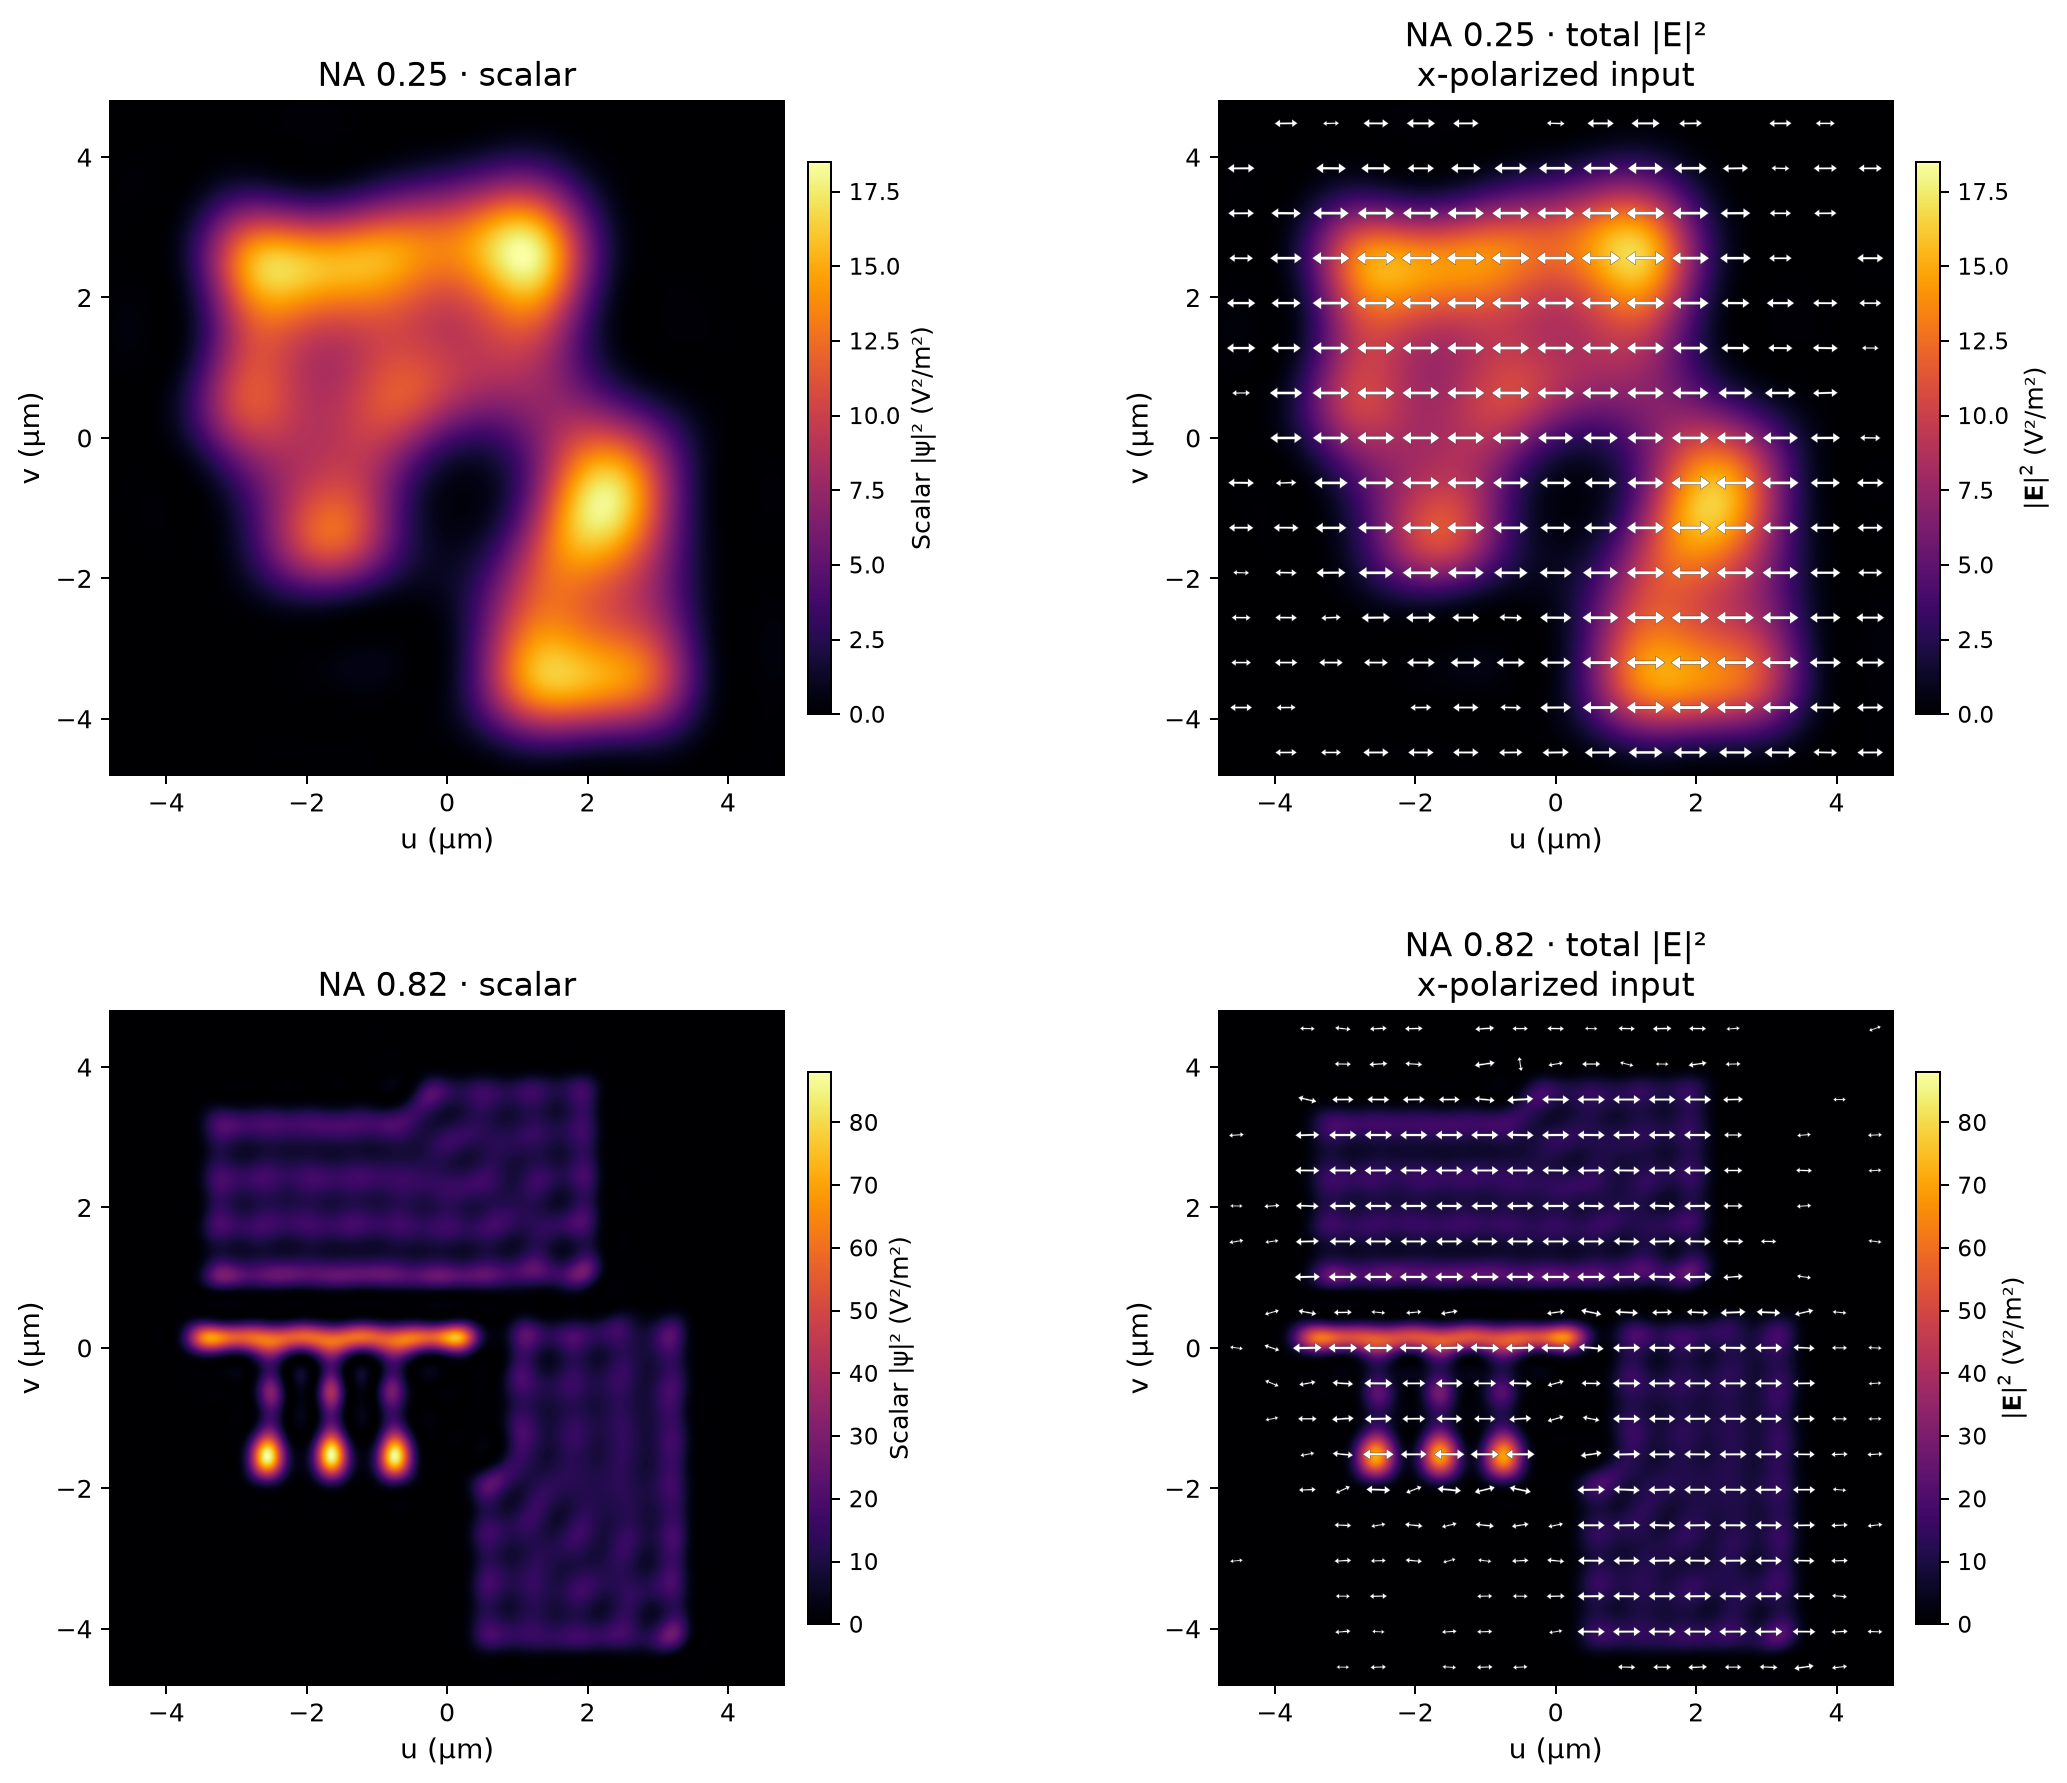

In [3]:
visible_images = []
figure, axes = plt.subplots(2, 2, figsize=(12, 11))
figure.subplots_adjust(
    left=0.07, right=0.93, bottom=0.10, top=0.90, wspace=0.48, hspace=0.35
)
for row, na in enumerate((0.25, 0.82)):
    vector, scalar, power = form_image(532e-9, -0.5, na, (1, 0), image_z=135 * um)
    view, rows, columns = field_window(vector, half_width=4.8 * um)
    scalar_view = scalar[rows][:, columns]
    norm = Normalize(0, max(view.norm2().max(), scalar_view.max()))
    plot_intensity(
        view,
        scalar_view,
        axis=axes[row, 0],
        norm=norm,
        title=f"NA {na:g} · scalar",
        label="Scalar |ψ|² (V²/m²)",
        polarization=False,
    )
    plot_intensity(
        view,
        axis=axes[row, 1],
        norm=norm,
        title=f"NA {na:g} · total |E|²\nx-polarized input",
        polarization=True,
    )
    visible_images.append((vector, scalar))
    print(f"Visible NA {na:g}: transmitted power {power * 1e12:.4f} pW")
plt.show()

## 2. DUV reduction with incoherent annular illumination

Now keep the **same physical reticle**, change to 193 nm, and use an ideal two-objective relay with $f_1=200$ mm and $f_2=50$ mm: $m=-f_2/f_1=-1/4$. Image NA 0.85 means object NA 0.2125. The object–objective–objective–image distances are 200 mm, 250 mm and 50 mm. This is an ideal angular-pupil representation of a 4f relay, not a fabricated multi-surface objective.

The source is an incoherent annulus of radius $\sigma=0.6$ relative to the object pupil. For directions $q_j$ and weights $w_j$,

$$I=\sum_j w_j|\mathbf E_j|^2,\qquad \mathbf S=\sum_jw_j\mathbf S_j.$$

Stokes values also add with $w_j$; phasors do not. A mixed source has no single optical phase to animate.

Refine 8 → 16 → 32 source angles, then check the displayed 32-direction image against 64 directions. The computational image spacing is 12.5 nm; this is separate from the source quadrature and the reticle's physical raster spacing.

In [4]:
wavelength = 193e-9
magnification = -0.25
image_na = 0.85
source_radius = 0.6 * abs(magnification) * image_na
source_cache = {}


def source_response(index, state):
    key = (index, tuple(state))
    if key not in source_cache:
        angle = 2 * np.pi * index / 32
        direction = source_radius * np.array([np.cos(angle), np.sin(angle)])
        source_cache[key] = form_image(
            wavelength,
            magnification,
            image_na,
            state,
            direction=direction,
            image_z=0.5,
        )

    return source_cache[key]


previous = None
for number in (8, 16, 32):
    indices = range(0, 32, 32 // number)
    responses = [source_response(index, (1, 0)) for index in indices]
    intensity = sum(response[0].norm2() for response in responses) / number
    if previous is not None:
        change = np.linalg.norm(intensity - previous) / np.linalg.norm(intensity)
        print(
            f"{number // 2} → {number} source angles: intensity change = {change:.3%}"
        )
    previous = intensity

x_responses = [source_response(index, (1, 0)) for index in range(32)]
y_responses = [source_response(index, (0, 1)) for index in range(32)]
x_fields = [response[0] for response in x_responses]
y_fields = [response[0] for response in y_responses]
scalar = sum(response[1] for response in x_responses) / 32
weights = np.full(32, 1 / 32)
assert np.allclose(scalar, sum(response[1] for response in y_responses) / 32)
for label, group in (("x", x_responses), ("y", y_responses)):
    print(
        f"DUV {label}: mean transmitted normal power = {np.mean([r[2] for r in group]) * 1e12:.4f} pW"
    )

# Check the retained 32-direction image against a finer source quadrature.
# New directions contribute to the intensity sum without storing another ensemble.
reference_64 = previous / 2
for index in range(1, 64, 2):
    angle = 2 * np.pi * index / 64
    direction = source_radius * np.array([np.cos(angle), np.sin(angle)])
    response, _, _ = form_image(
        wavelength, magnification, image_na, (1, 0), direction=direction, image_z=0.5
    )
    reference_64 += response.norm2() / 64
change_64 = np.linalg.norm(reference_64 - previous) / np.linalg.norm(reference_64)
print(f"32 → 64 source angles: intensity change = {change_64:.3%}")

8 → 16 source angles: intensity change = 5.637%


16 → 32 source angles: intensity change = 2.239%


DUV x: mean transmitted normal power = 0.7131 pW
DUV y: mean transmitted normal power = 0.7123 pW


32 → 64 source angles: intensity change = 0.750%


## 3. The circuit image and the regions to inspect

These are **aerial electric intensities**, not absorbed dose. All three panels share an absolute scale. The geometric inversion and 4× reduction follow the signed imaging map. Titles identify the input polarization; vector intensities sum all three electric components.

The boxes identify the two trace groups of the reticle, mapped through the signed 4× reduction: V contains mostly vertical traces; H contains mostly horizontal traces. Their enlarged images below reveal differences that a dense full-circuit overview cannot show clearly.

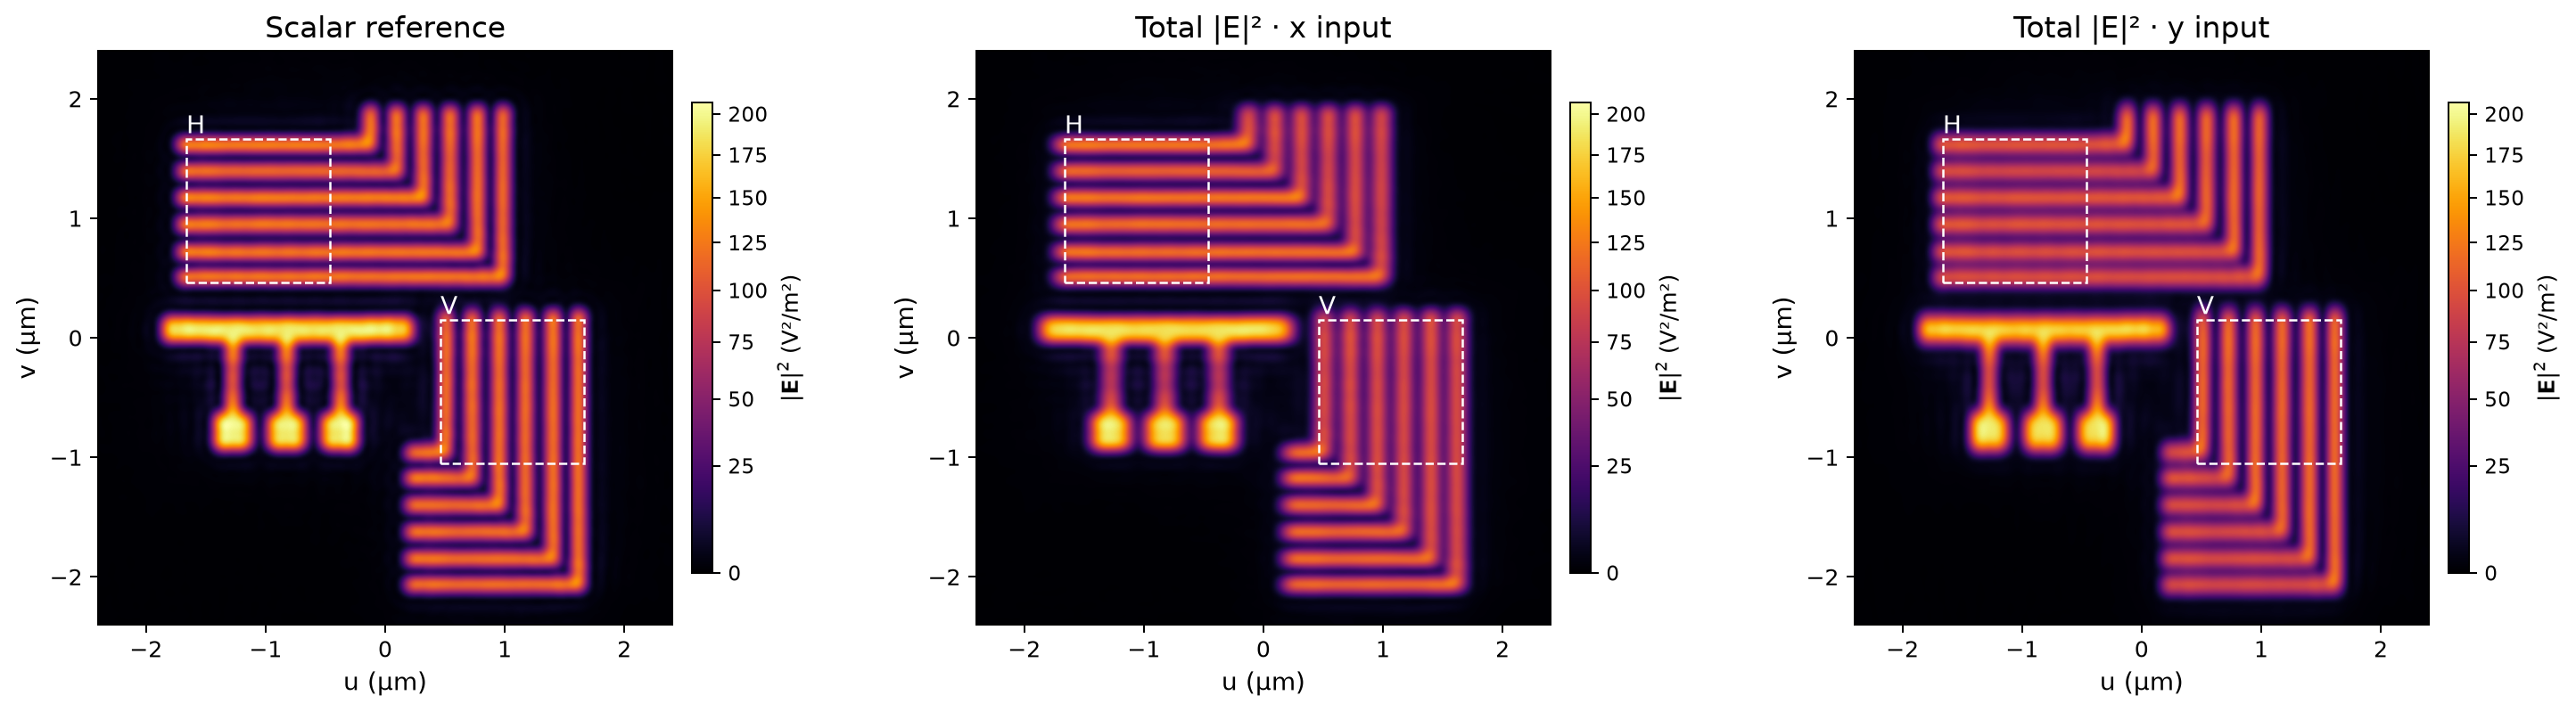

In [5]:
# Reticle centres and half-widths (µm), mapped to the wafer by the magnification.
regions = tuple(
    (
        name,
        (magnification * cx * um, magnification * cy * um),
        abs(magnification) * h * um,
    )
    for name, (cx, cy), h in (
        ("V · vertical traces", (-4.25, 1.8), 2.4),
        ("H · horizontal traces", (4.25, -4.25), 2.4),
    )
)
x_views = [field_window(field)[0] for field in x_fields]
y_views = [field_window(field)[0] for field in y_fields]
diagonal_fields = [
    optics.ElectricField(
        first.grid,
        first.wavelength0,
        (first.values + second.values) / np.sqrt(2),
    )
    for first, second in zip(x_fields, y_fields)
]
_, rows, columns = field_window(x_fields[0])
scalar_view = scalar[rows][:, columns]
x_intensity = sum(w * field.norm2() for w, field in zip(weights, x_views))
y_intensity = sum(w * field.norm2() for w, field in zip(weights, y_views))
maximum = max(scalar_view.max(), x_intensity.max(), y_intensity.max())

figure, axes = plt.subplots(1, 3, figsize=(16.5, 6))
figure.subplots_adjust(left=0.05, right=0.93, bottom=0.14, top=0.88, wspace=0.53)
for axis, group, background, title in zip(
    axes,
    (x_views, x_views, y_views),
    (scalar_view, x_intensity, y_intensity),
    (
        "Scalar reference",
        "Total |E|² · x input",
        "Total |E|² · y input",
    ),
):
    plot_intensity(
        group,
        background,
        weights=weights,
        axis=axis,
        norm=PowerNorm(0.7, 0, maximum),
        title=title,
        polarization=False,
    )
    for name, center, half_width in regions:
        axis.add_patch(
            Rectangle(
                ((center[0] - half_width) / um, (center[1] - half_width) / um),
                2 * half_width / um,
                2 * half_width / um,
                fill=False,
                edgecolor="white",
                linewidth=1,
                linestyle="--",
            )
        )
        axis.text(
            (center[0] - half_width) / um,
            (center[1] + half_width) / um,
            name[0],
            color="white",
            va="bottom",
            fontsize=11,
        )
plt.show()

## 4. Resolve polarization-dependent contrast on the trace groups

A global overview alone can conceal the difference between polarization along and across a narrow trace. Here each row uses the **same physical window and intensity scale** in all three models. These scalar/x-input/y-input panels compare image intensity, so they contain no polarization glyphs. The x and y labels identify separate illumination experiments; they are not electric-field components.

The scalar result is insensitive to x versus y input. In a vector calculation, changing the input state changes longitudinal field generation and the interference of oblique orders. This is why the two trace orientations are useful controls. A separate figure below uses coherent diagonal illumination and places its polarization map over the **total** vector intensity of that same field.

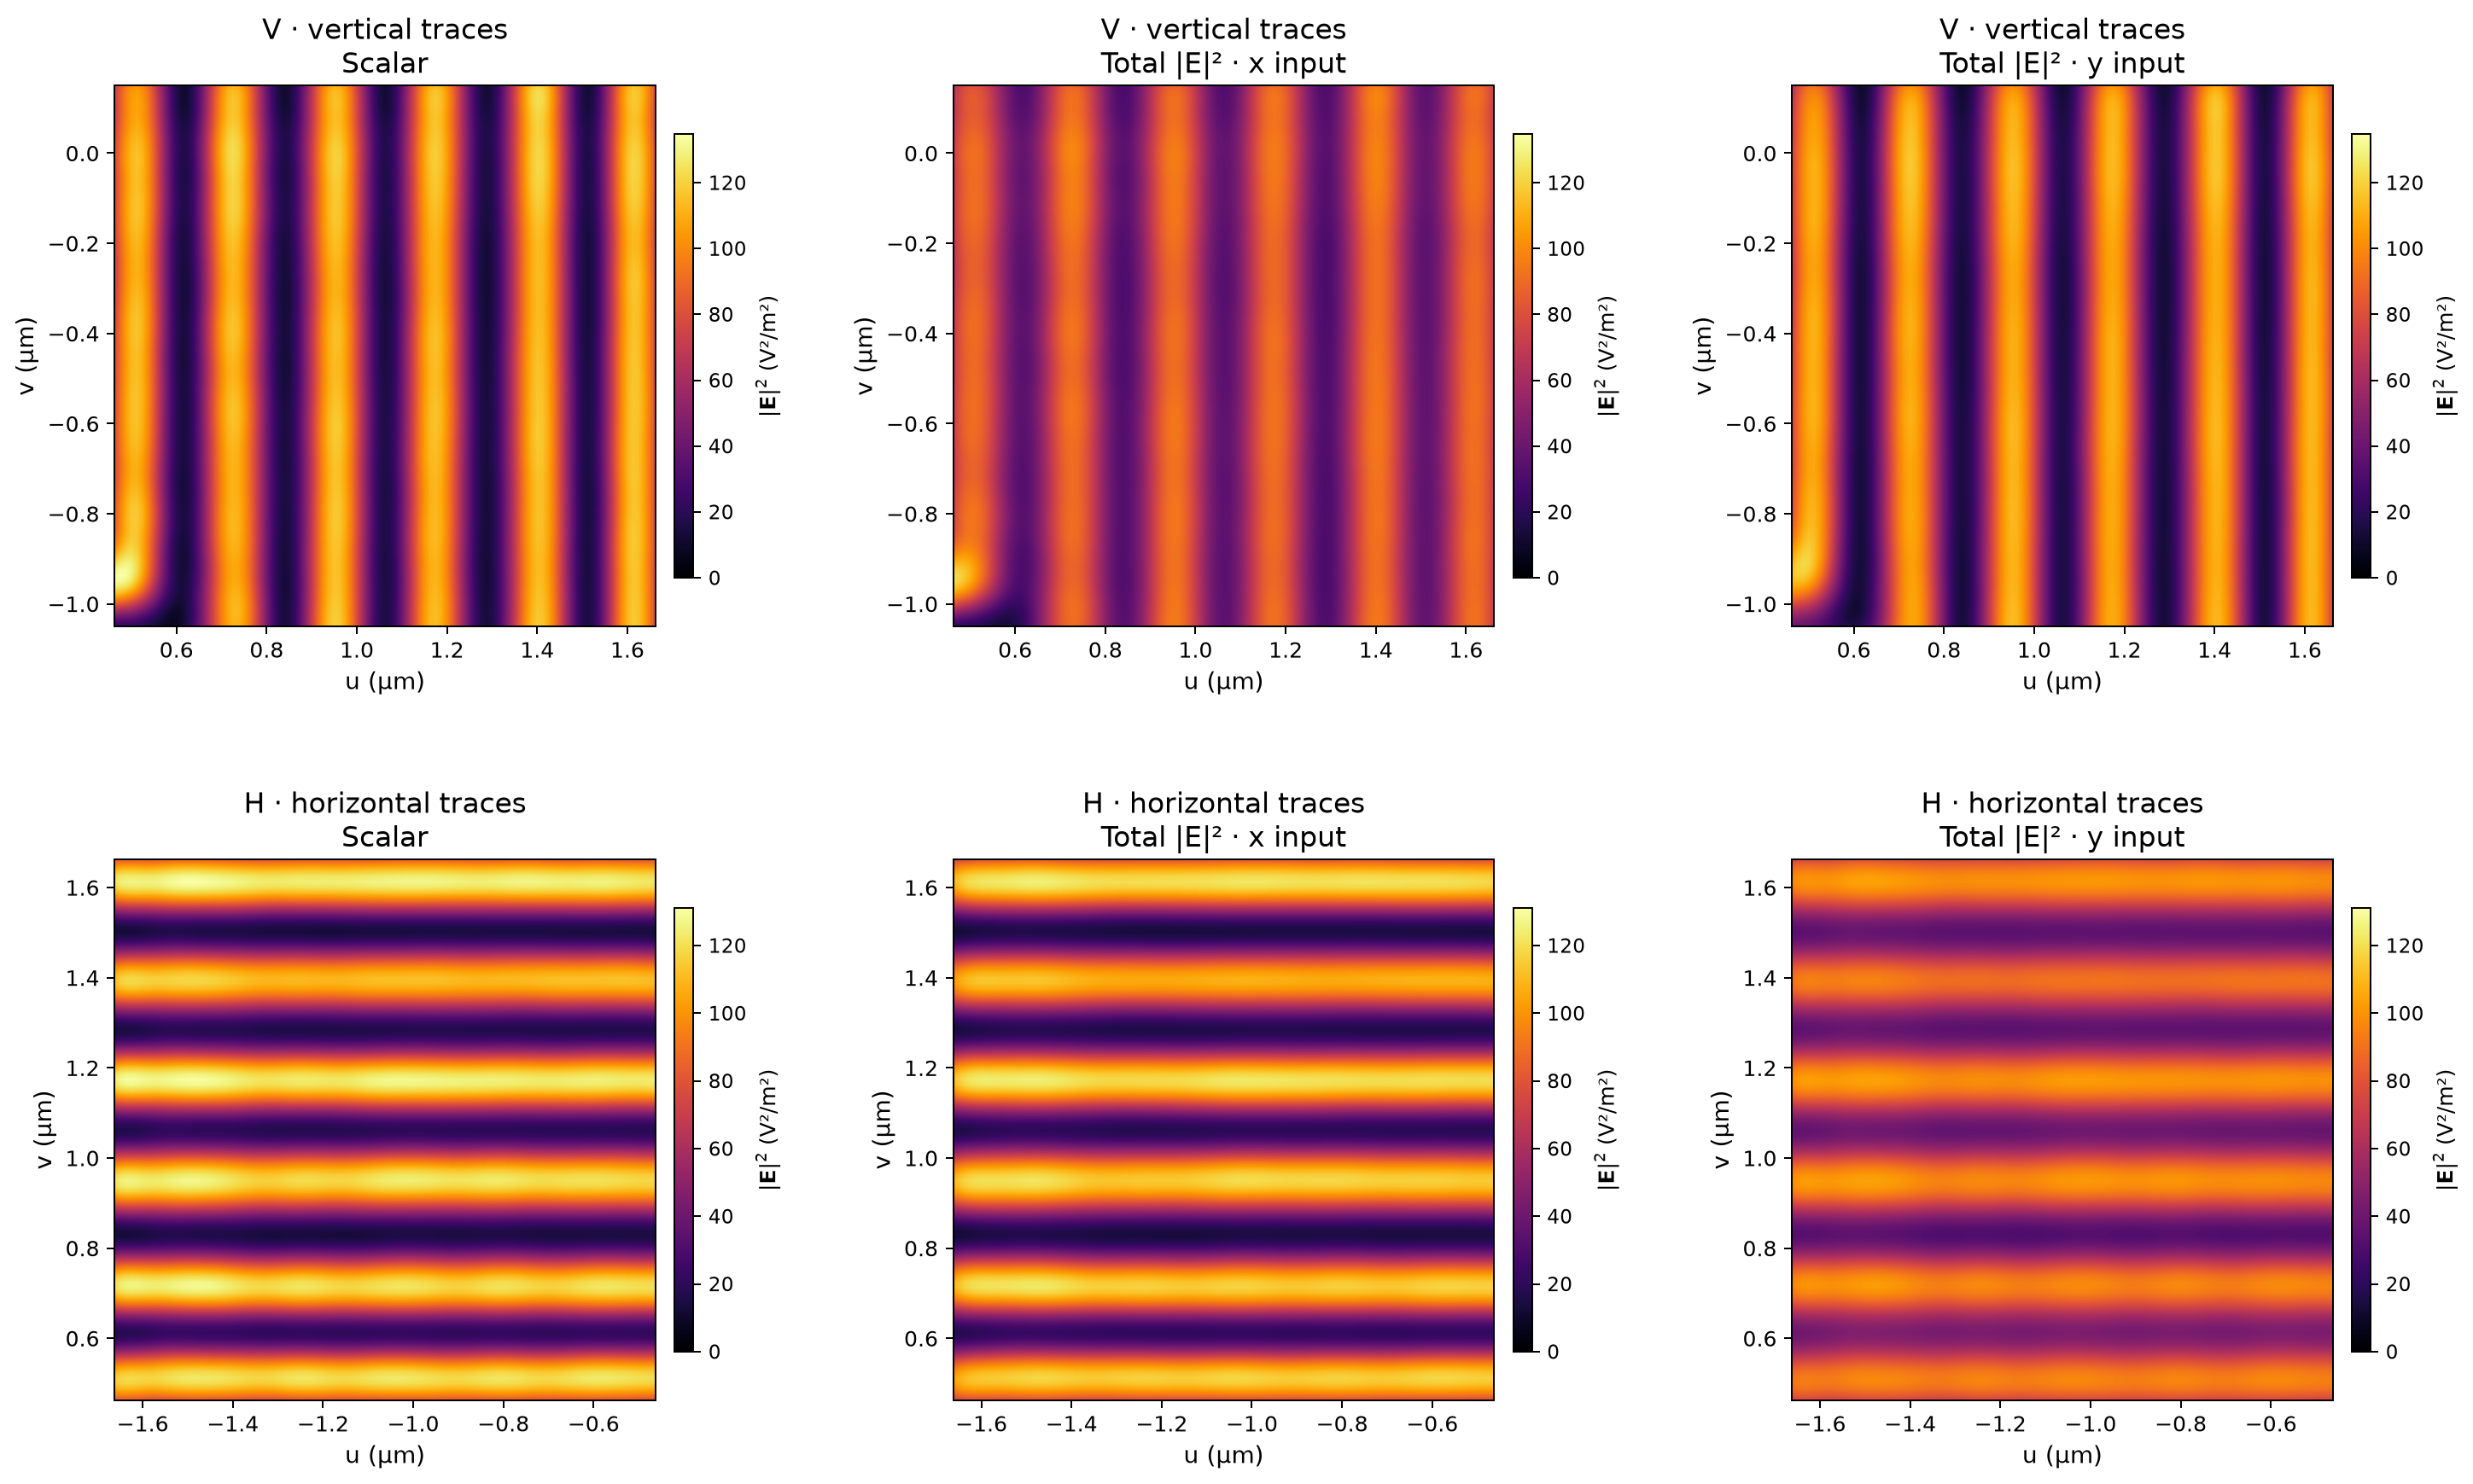

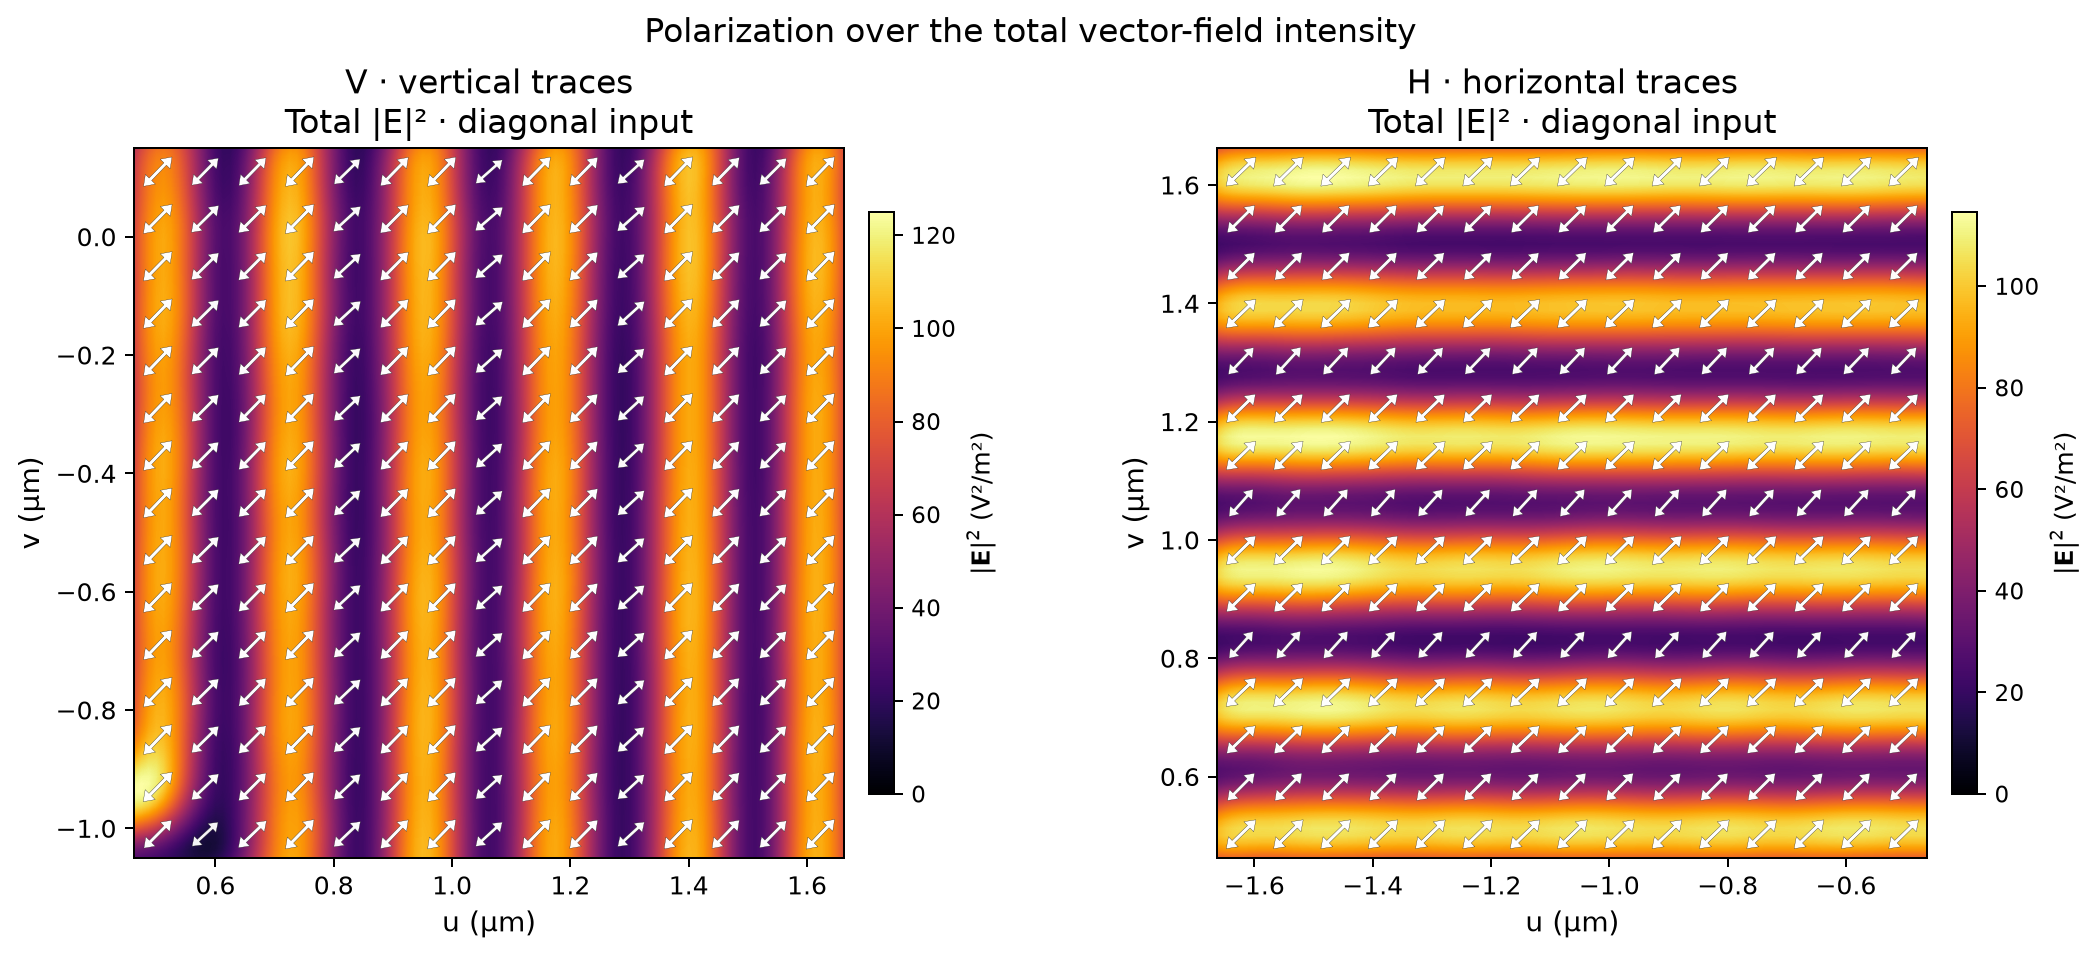

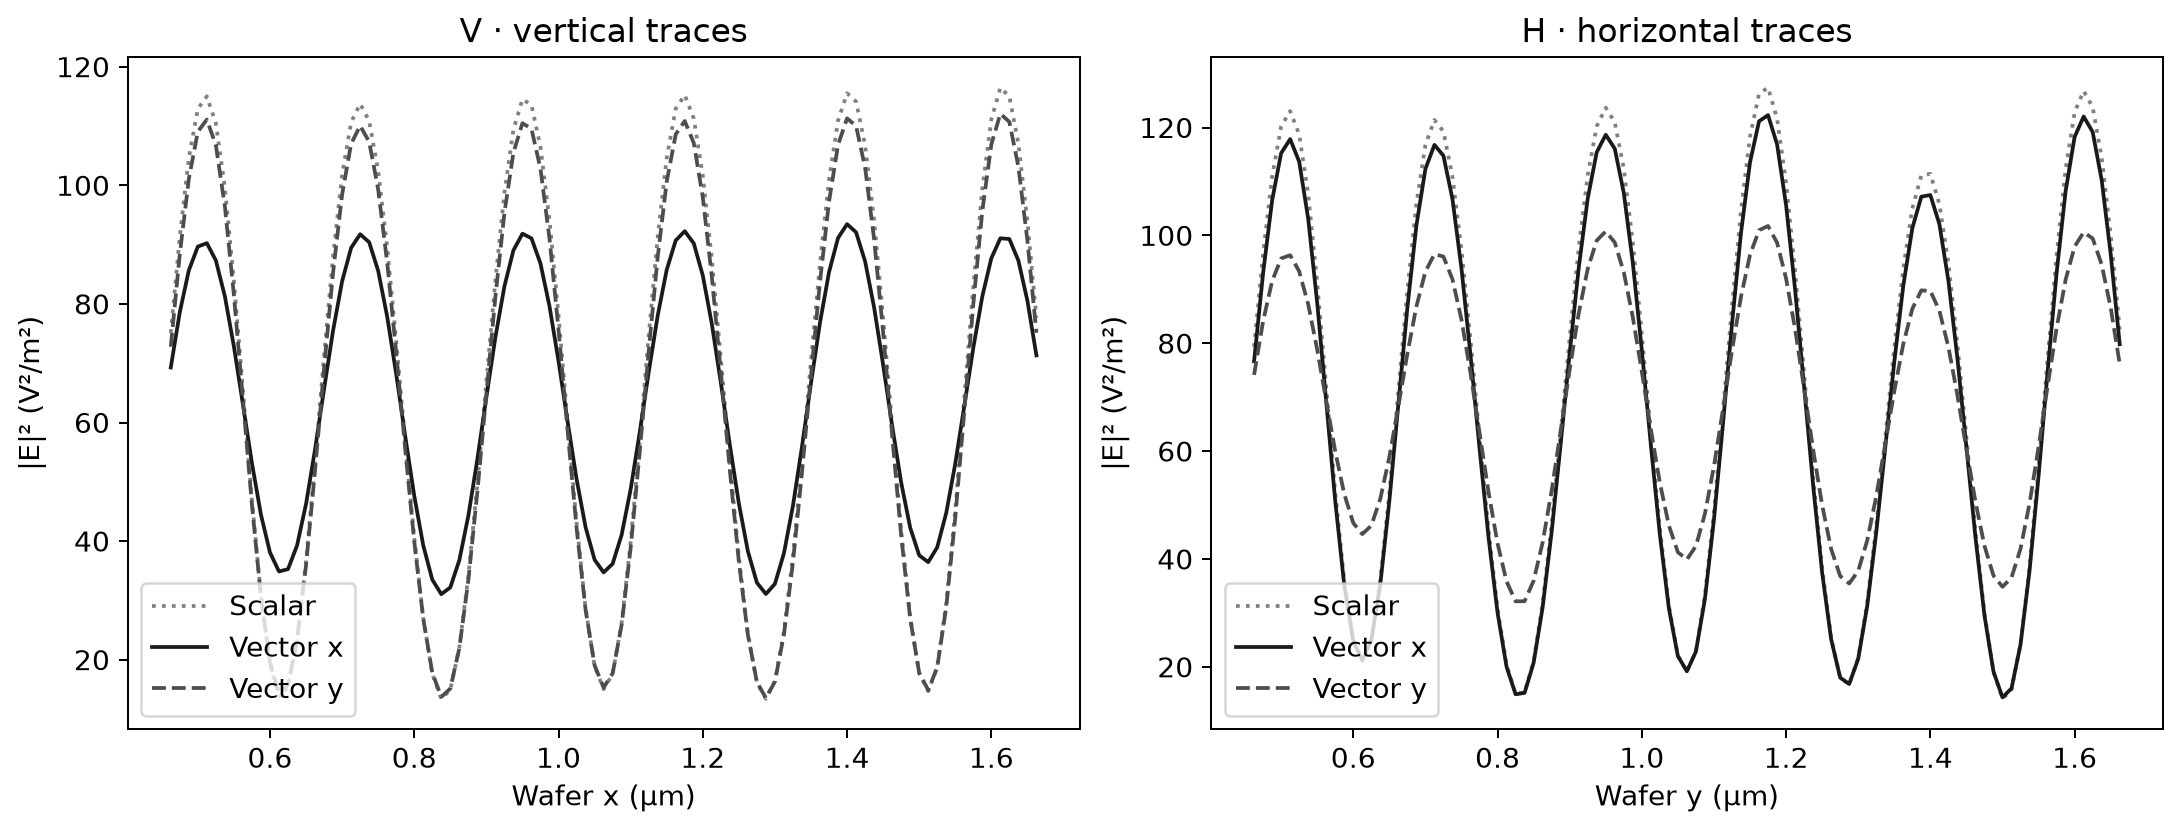

In [6]:
figure, axes = plt.subplots(2, 3, figsize=(16.5, 10.5))
figure.subplots_adjust(
    left=0.055, right=0.93, bottom=0.09, top=0.92, wspace=0.55, hspace=0.37
)
profiles = []
for row, (name, center, half_width) in enumerate(regions):
    vx = [field_window(field, center, half_width)[0] for field in x_fields]
    vy = [field_window(field, center, half_width)[0] for field in y_fields]
    _, rows, columns = field_window(x_fields[0], center, half_width)
    scalar_window = scalar[rows][:, columns]
    ix = sum(w * f.norm2() for w, f in zip(weights, vx))
    iy = sum(w * f.norm2() for w, f in zip(weights, vy))
    norm = Normalize(0, max(scalar_window.max(), ix.max(), iy.max()))
    for column, (group, intensity, label) in enumerate(
        zip(
            (vx, vx, vy),
            (scalar_window, ix, iy),
            ("Scalar", "Total |E|² · x input", "Total |E|² · y input"),
        )
    ):
        plot_intensity(
            group,
            intensity,
            weights=weights,
            axis=axes[row, column],
            norm=norm,
            title=f"{name}\n{label}",
            polarization=False,
        )
    profiles.append((vx[0].grid, scalar_window, ix, iy))
plt.show()

# Polarization belongs to a complete vector field, not to the separate
# x/y intensity-comparison panels above. Coherently superpose the two
# responses for a diagonal input, source direction by source direction.
figure, axes = plt.subplots(1, 2, figsize=(12, 5.2), layout="constrained")
for axis, (name, center, half_width) in zip(axes, regions):
    diagonal_view = [
        field_window(field, center, half_width)[0] for field in diagonal_fields
    ]
    total_intensity = sum(w * field.norm2() for w, field in zip(weights, diagonal_view))
    plot_intensity(
        diagonal_view,
        total_intensity,
        weights=weights,
        axis=axis,
        norm=Normalize(0, total_intensity.max()),
        title=f"{name}\nTotal |E|² · diagonal input",
    )
figure.suptitle("Polarization over the total vector-field intensity")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for row, (axis, (view_grid, scalar_window, ix, iy)) in enumerate(zip(axes, profiles)):
    if row == 0:
        index = len(view_grid.v) // 2
        coordinate = view_grid.u / um
        values = (scalar_window[index], ix[index], iy[index])
        label = "Wafer x (µm)"
    else:
        index = len(view_grid.u) // 2
        coordinate = view_grid.v / um
        values = (scalar_window[:, index], ix[:, index], iy[:, index])
        label = "Wafer y (µm)"
    for value, name, style, gray in zip(
        values,
        ("Scalar", "Vector x", "Vector y"),
        (":", "-", "--"),
        ("0.5", "0.1", "0.3"),
    ):
        axis.plot(coordinate, value, style, color=gray, label=name)
    axis.set(xlabel=label, ylabel="|E|² (V²/m²)", title=regions[row][0])
    axis.legend()
plt.show()

## What remains to check before treating this as a process prediction

The source-angle changes printed above measure **one** numerical sensitivity. Mask rasterization, spatial window and pupil sampling must also be refined for quantitative edge-placement claims. The paired intensity scales and line profiles do not constitute a resist model or a manufacturing tolerance.

This experiment preserves the circuit pattern and its physical scale, while changing polarization, aperture, wavelength and reduction explicitly. A real DUV objective needs a traced or measured Jones pupil and the appropriate mask-field calculation. [Ansys's lithography methodology](https://optics.ansys.com/hc/en-us/articles/360042256993-Lithography-Methodology) gives useful context for separating these stages.